In [30]:
import pickle
import os
from sv_spline.diagnostics import *
from sv_spline.data import *
import numpy as np

In [2]:
with open('results/simulation_bitcoin/simulation_bitcoin_results.pkl', 'rb') as f:
    results = pickle.load(f)

In [10]:
df = results['df']
split_date = results['config']['SPLIT_DATE']
basic_results = results['res_basic']
semi_results = results['res_semi']

In [21]:
df

,Date,Close,market_cap,total_volume,Returns,Log Returns
0,2014-01-01 00:00:00+00:00,767.740000,9.358693e+09,2.344860e+07,0.016659,0.016521
1,2014-01-02 00:00:00+00:00,772.530000,9.417083e+09,1.683780e+07,0.006239,0.006220
2,2014-01-03 00:00:00+00:00,825.470000,1.006242e+10,5.417150e+07,0.068528,0.066282
3,2014-01-04 00:00:00+00:00,849.140000,1.035095e+10,3.634470e+07,0.028675,0.028271
4,2014-01-05 00:00:00+00:00,919.410000,1.120754e+10,6.241460e+07,0.082754,0.079508
...,...,...,...,...,...,...
4412,2026-01-31 00:00:00+00:00,84141.778570,1.680808e+12,7.951546e+10,-0.005068,-0.005081
4413,2026-02-01 00:00:00+00:00,78725.858539,1.573735e+12,7.848854e+10,-0.064367,-0.066532
4414,2026-02-02 00:00:00+00:00,76937.064066,1.537520e+12,5.833074e+10,-0.022722,-0.022984
4415,2026-02-03 00:00:00+00:00,78767.658153,1.573217e+12,8.467513e+10,0.023793,0.023515


In [11]:
basic_results

{'params_history': {'alpha': array([0.00109156, 0.00109156, 0.00144262, ..., 0.00116308, 0.00116308,
         0.00129275]),
  'log_sigma2': array([-1.93384476, -1.93384476, -1.91349099, ..., -0.53676376,
         -0.53676376, -0.51128395]),
  'phi': array([0.90211954, 0.90211954, 0.90325578, ..., 0.8231615 , 0.8231615 ,
         0.81704077]),
  'mu': array([-6.43980274, -6.43980274, -6.48161464, ..., -7.2807542 ,
         -7.2807542 , -7.21752132])},
 'll_history': array([5192.42043217, 5192.42043217, 5200.09650078, ..., 5277.39365531,
        5277.39365531, 5274.40561507]),
 'acceptance_rates': {0: 0.2720000000000002},
 'n_warmup': 1000,
 'n_iter': 2000,
 'model': <sv_spline.models.BasicSV at 0x1041585e0>}

In [26]:
df_train, df_test = split_data(df,split_date=split_date)
T_train = len(df_train)
df_reduce = df[
    df["Date"] <= pd.to_datetime(split_date, utc=True) + pd.Timedelta(days=120)
]
y = get_y(df_reduce)

In [24]:
df_reduce

,Date,Close,market_cap,total_volume,Returns,Log Returns
0,2014-01-01 00:00:00+00:00,767.740000,9.358693e+09,2.344860e+07,0.016659,0.016521
1,2014-01-02 00:00:00+00:00,772.530000,9.417083e+09,1.683780e+07,0.006239,0.006220
2,2014-01-03 00:00:00+00:00,825.470000,1.006242e+10,5.417150e+07,0.068528,0.066282
3,2014-01-04 00:00:00+00:00,849.140000,1.035095e+10,3.634470e+07,0.028675,0.028271
4,2014-01-05 00:00:00+00:00,919.410000,1.120754e+10,6.241460e+07,0.082754,0.079508
...,...,...,...,...,...,...
2672,2021-04-27 00:00:00+00:00,53978.805547,1.008390e+12,6.022693e+10,0.102026,0.097150
2673,2021-04-28 00:00:00+00:00,54991.814843,1.027618e+12,4.846856e+10,0.018767,0.018593
2674,2021-04-29 00:00:00+00:00,54810.613851,1.024626e+12,4.807293e+10,-0.003295,-0.003300
2675,2021-04-30 00:00:00+00:00,53596.704023,1.001974e+12,4.695804e+10,-0.022147,-0.022396


In [18]:
pmmh_summary(basic_results)

,Parameter,Mean,Std,Quantile 2.5%,Quantile 97.5%
0,alpha,0.001240,0.000420,0.000559,0.002133
1,log_sigma2,-0.585502,0.169976,-0.890189,-0.302856
2,phi,0.837946,0.025725,0.791144,0.882367
3,mu,-7.366670,0.112821,-7.580344,-7.138870


In [27]:
pred_outputs_basic = predictive_outputs(basic_results, y_full=y, x_full=None, T_train=T_train, rng=None)
pit_basic_test=pred_outputs_basic['pit_test']
print("Ljung-Box test for Basic SV model:")
lb_test_basic, lb_test_sq_basic = ljungbox(pit_basic_test, lags=[5,10])
print("Ljung-Box test for residuals of Basic SV model:")
print(lb_test_basic)
print("Ljung-Box test for squared residuals of Basic SV model:")
print(lb_test_sq_basic)

Ljung-Box test for Basic SV model:
Ljung-Box test for residuals of Basic SV model:
     lb_stat  lb_pvalue
5   1.402635   0.924025
10  8.380415   0.591731
Ljung-Box test for squared residuals of Basic SV model:
      lb_stat  lb_pvalue
5    8.602417   0.126013
10  17.129104   0.071556


In [28]:
comparaison_oos = compare_oos(basic_results, semi_results, y_full=y, x_full=None, T_train=T_train, seed=42)

In [29]:
comparaison_oos

,Model,Log Score Test,KS Test p-value,Ljung-Box Test (Residuals) p-value,Ljung-Box Test (Squared Residuals) p-value
0,Basic SV,196.818259,0.383629,0.615777,0.051165
1,Semiparametric SV,198.126828,0.597199,0.612947,0.093396


### KS TEST : 

H0 : il existe une difference statistiquement significative entre les distributions comparées. 
Pour le PIT, on fait un ks test sur la loi uniforme pour savoir si le modèle est bien calibré. Si p_value supérieur < 0.05, le modèle est mal calibré.

### Ljung Box :

H0 : Les résidus présentent une autocorrelation significative, le modèle n'a pas capté toute l'information.
Si pvalue inferieur à 0.05, le modèle n'a pas tt l'info



À quoi correspondent les résidus et leurs carrés ?

• Les résidus standardisés z_t = epsilon_t / sigma_t : ils représentent les « chocs » ou innovations une fois que l'on a filtré l'effet de la moyenne et divisé par la volatilité estimée sigma_t. Si le modèle est bon, ils doivent se comporter comme un bruit blanc indépendant et identiquement distribué (i.i.d.).
• Les carrés des résidus standardisés z_t^2$ : ils servent de mesure (proxy) pour la variance résiduelle (l'ampleur des chocs, indépendamment de leur signe). Tester leur autocorrélation permet de vérifier s'il reste des « grappes de volatilité » (volatility clustering) non capturées par le modèle.


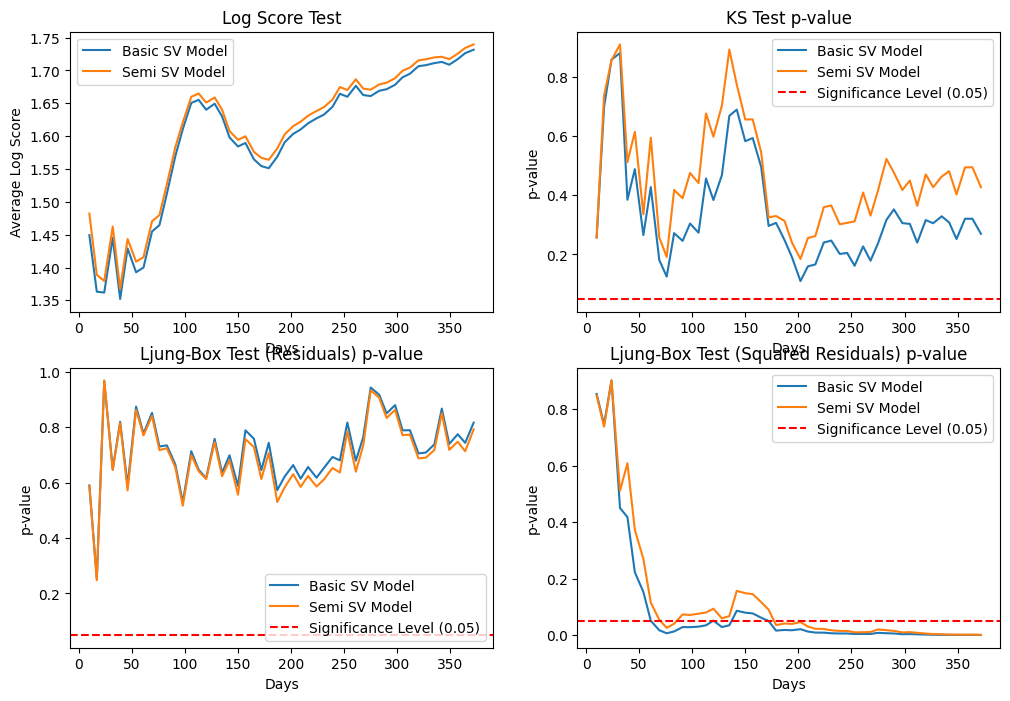

In [42]:
days_test= np.linspace(10, len(df_test)//5, 50, dtype=int)
log_scores_basic = []
log_scores_semi = []
ks_test_basic = []
ks_test_semi = []
ljung_box_basic = []
ljung_box_semi = []
ljung_box_basic_squared = []
ljung_box_semi_squared = []
for day in days_test:
    df_reduce = df[
        df["Date"] <= pd.to_datetime(split_date, utc=True) + pd.Timedelta(days=day)
    ]
    y = get_y(df_reduce)
    comparaison_oos = compare_oos(basic_results, semi_results, y_full=y, x_full=None, T_train=T_train, seed=42)
    log_scores_basic.append(comparaison_oos["Log Score Test"][0]/day)
    log_scores_semi.append(comparaison_oos["Log Score Test"][1]/day)
    ks_test_basic.append(comparaison_oos["KS Test p-value"][0])
    ks_test_semi.append(comparaison_oos["KS Test p-value"][1])
    ljung_box_basic.append(comparaison_oos["Ljung-Box Test (Residuals) p-value"][0])
    ljung_box_semi.append(comparaison_oos["Ljung-Box Test (Residuals) p-value"][1])
    ljung_box_basic_squared.append(comparaison_oos["Ljung-Box Test (Squared Residuals) p-value"][0])
    ljung_box_semi_squared.append(comparaison_oos["Ljung-Box Test (Squared Residuals) p-value"][1])

plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plt.plot(days_test, log_scores_basic, label="Basic SV Model")
plt.plot(days_test, log_scores_semi, label="Semi SV Model")
plt.title("Log Score Test")
plt.xlabel("Days")
plt.ylabel("Average Log Score")
plt.legend()

plt.subplot(2, 2, 2)
plt.plot(days_test, ks_test_basic, label="Basic SV Model")
plt.plot(days_test, ks_test_semi, label="Semi SV Model")
plt.axhline(y=0.05, color='r', linestyle='--', label='Significance Level (0.05)')
plt.title("KS Test p-value")
plt.xlabel("Days")
plt.ylabel("p-value")
plt.legend()

plt.subplot(2, 2, 3)
plt.plot(days_test, ljung_box_basic, label="Basic SV Model")
plt.plot(days_test, ljung_box_semi, label="Semi SV Model")
plt.axhline(y=0.05, color='r', linestyle='--', label='Significance Level (0.05)')
plt.title("Ljung-Box Test (Residuals) p-value")
plt.xlabel("Days")
plt.ylabel("p-value")
plt.legend()

plt.subplot(2, 2, 4)
plt.plot(days_test, ljung_box_basic_squared, label="Basic SV Model")
plt.plot(days_test, ljung_box_semi_squared, label="Semi SV Model")
plt.axhline(y=0.05, color='r', linestyle='--', label='Significance Level (0.05)')
plt.title("Ljung-Box Test (Squared Residuals) p-value")
plt.xlabel("Days")
plt.ylabel("p-value")
plt.legend()